# Telemetry Log Parser and Detection Visualizer

This notebook parses telemetry log files and visualizes detections on images.

In [1]:
import re
import os
from datetime import datetime
from typing import List, Dict, Tuple
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

## Configuration

In [2]:
# Configuration
LOG_FILE = 'logs_of_GW_52.txt'  # Change this to your log file name
IMGS_FOLDER = 'imgs'
CURRENT_DIR = Path('.')

## Parse Log File

In [3]:
class Detection:
    """Represents a single detection"""
    def __init__(self, pixel_x, pixel_y, cm_x, cm_y, conf, box_x, box_y, box_w, box_h, sensor_id,
                 label="translated", gmm_label=None):
        self.pixel_x = pixel_x
        self.pixel_y = pixel_y
        self.cm_x = cm_x
        self.cm_y = cm_y
        self.confidence = conf
        self.box_x = box_x
        self.box_y = box_y
        self.box_w = box_w
        self.box_h = box_h
        self.sensor_id = sensor_id
        self.label = label
        self.gmm_label = gmm_label
    
    def __repr__(self):
        pixel = (
            f"{self.pixel_x},{self.pixel_y}"
            if self.pixel_x is not None and self.pixel_y is not None
            else "None"
        )
        cm = (
            f"{self.cm_x},{self.cm_y}"
            if self.cm_x is not None and self.cm_y is not None
            else "None"
        )
        gmm = f", gmm={self.gmm_label}" if self.gmm_label else ""
        return (
            f"Detection(label={self.label}{gmm}, "
            f"pixel=({pixel}), cm=({cm}), "
            f"box=({self.box_x},{self.box_y},{self.box_w},{self.box_h}), "
            f"conf={self.confidence:.3f})"
        )

class TelemetryMessage:
    """Represents a telemetry message with detections"""
    def __init__(self, timestamp, sensor_id, length):
        self.timestamp = timestamp
        self.sensor_id = sensor_id
        self.length = length
        self.detections = []
    
    def add_detection(self, detection):
        self.detections.append(detection)

    def plot(self, ax=None, colors=None, show_pixels=True, show_conf=True, title=None, image_path=None):
        """Plot detections in pixel coordinates with top-left origin."""
        import matplotlib.pyplot as plt
        from matplotlib.patches import Rectangle
        import matplotlib.image as mpimg

        if colors is None:
            colors = {
                "translated": "tab:blue",
                "gmm_filtered": "tab:red",
            }

        if ax is None:
            _, ax = plt.subplots()

        # Fixed 320x240 canvas, origin at top-left
        ax.set_xlim(0, 320)
        ax.set_ylim(240, 0)
        ax.set_aspect("equal", adjustable="box")

        if image_path is not None:
            img = mpimg.imread(image_path)
            ax.imshow(img, extent=(0, 320, 240, 0))

        for det in self.detections:
            color = colors.get(det.label, "gray")
            rect = Rectangle(
                (det.box_x, det.box_y),
                det.box_w,
                det.box_h,
                fill=False,
                linewidth=2,
                edgecolor=color,
            )
            ax.add_patch(rect)

            if show_pixels and det.pixel_x is not None and det.pixel_y is not None:
                ax.scatter([det.pixel_x], [det.pixel_y], s=20, color=color)

            if show_conf:
                ax.text(
                    det.box_x + det.box_w,
                    det.box_y,
                    f"{det.confidence:.2f}",
                    ha="right",
                    va="top",
                    color=color,
                    fontsize=8,
                    bbox=dict(facecolor="white", alpha=0.6, edgecolor="none", pad=1),
                )

        ax.set_title(title or f"{self.sensor_id} @ {self.timestamp}")
        ax.set_xlabel("x (px)")
        ax.set_ylabel("y (px)")
        return ax
    def __repr__(self):
        return (f"TelemetryMessage(timestamp={self.timestamp}, "
                f"sensor={self.sensor_id}, "
                f"detections={len(self.detections)})")


In [4]:
def parse_log_file(log_file_path: str) -> List[TelemetryMessage]:
    """
    Parse the log file and extract telemetry messages with their detections.
    
    Args:
        log_file_path: Path to the log file
        
    Returns:
        List of TelemetryMessage objects
    """
    # Regular expressions for parsing
    telemetry_pattern = re.compile(
        r'(\w{3}\s+\d{2}\s+\d{2}:\d{2}:\d{2}).*Received telemetry data, length: (\d+), from thing ([\w\-]+)'
    )
    
    detection_pattern = re.compile(
        r'(\w{3}\s+\d{2}\s+\d{2}:\d{2}:\d{2}).*Detection translated for sensor ([\w\-]+): '
        r'pixel\((\d+),(\d+)\) -> cm\((-?\d+),(-?\d+)\). '
        r'conf = ([\d.]+); box: x = (\d+), y = (\d+), w = (\d+), h = (\d+)'
    )

    gmm_filtered_pattern = re.compile(
        r'(\w{3}\s+\d{2}\s+\d{2}:\d{2}:\d{2}).*Detection filtered out by GMM: (\w+) '
        r'\(x=(\d+), y=(\d+), w=(\d+), h=(\d+), conf=([\d.]+)\)'
    )
    
    telemetry_messages = []
    current_message = None
    
    with open(log_file_path, 'r') as f:
        for line in f:
            # Check for telemetry message
            telemetry_match = telemetry_pattern.search(line)
            if telemetry_match:
                # Save previous message if it exists
                if current_message is not None:
                    telemetry_messages.append(current_message)
                
                # Create new message
                timestamp = telemetry_match.group(1)
                length = int(telemetry_match.group(2))
                sensor_id = telemetry_match.group(3)
                current_message = TelemetryMessage(timestamp, sensor_id, length)
                continue
            
            # Check for translated detection
            detection_match = detection_pattern.search(line)
            if detection_match and current_message is not None:
                timestamp = detection_match.group(1)
                sensor_id = detection_match.group(2)
                pixel_x = int(detection_match.group(3))
                pixel_y = int(detection_match.group(4))
                cm_x = int(detection_match.group(5))
                cm_y = int(detection_match.group(6))
                conf = float(detection_match.group(7))
                box_x = int(detection_match.group(8))
                box_y = int(detection_match.group(9))
                box_w = int(detection_match.group(10))
                box_h = int(detection_match.group(11))
                
                detection = Detection(
                    pixel_x, pixel_y, cm_x, cm_y, conf,
                    box_x, box_y, box_w, box_h, sensor_id,
                    label="translated"
                )
                current_message.add_detection(detection)
                continue

            # Check for GMM-filtered detection
            gmm_match = gmm_filtered_pattern.search(line)
            if gmm_match and current_message is not None:
                timestamp = gmm_match.group(1)
                gmm_label = gmm_match.group(2)
                box_x = int(gmm_match.group(3))
                box_y = int(gmm_match.group(4))
                box_w = int(gmm_match.group(5))
                box_h = int(gmm_match.group(6))
                conf = float(gmm_match.group(7))

                detection = Detection(
                    None, None, None, None, conf,
                    box_x, box_y, box_w, box_h, current_message.sensor_id,
                    label="gmm_filtered", gmm_label=gmm_label
                )
                current_message.add_detection(detection)
    
    # Don't forget the last message
    if current_message is not None:
        telemetry_messages.append(current_message)
    
    return telemetry_messages


In [5]:
# Parse the log file
log_path = CURRENT_DIR / LOG_FILE
telemetry_messages = parse_log_file(log_path)

print(f"Parsed {len(telemetry_messages)} telemetry messages")
print(f"\nFirst 5 messages:")
for i, msg in enumerate(telemetry_messages[:5]):
    print(f"{i+1}. {msg}")
    for det in msg.detections:
        print(f"   - {det}")

Parsed 35 telemetry messages

First 5 messages:
1. TelemetryMessage(timestamp=Feb 25 09:31:30, sensor=6000401-1221-012345-4040, detections=4)
   - Detection(label=translated, pixel=(219,67), cm=(113,112), box=(191,25,56,66), conf=0.874)
   - Detection(label=translated, pixel=(265,58), cm=(239,153), box=(245,28,58,46), conf=0.685)
   - Detection(label=translated, pixel=(245,175), cm=(172,-102), box=(220,145,55,62), conf=0.596)
   - Detection(label=translated, pixel=(196,104), cm=(63,37), box=(166,77,57,57), conf=0.404)
2. TelemetryMessage(timestamp=Feb 25 09:31:31, sensor=6000209-1221-012345-4040, detections=0)
3. TelemetryMessage(timestamp=Feb 25 09:31:38, sensor=6000303-1221-012345-4040, detections=0)
4. TelemetryMessage(timestamp=Feb 25 09:31:41, sensor=6000401-1221-012345-4040, detections=4)
   - Detection(label=translated, pixel=(220,67), cm=(115,112), box=(191,25,57,64), conf=0.874)
   - Detection(label=translated, pixel=(267,58), cm=(246,154), box=(244,28,59,48), conf=0.685)
   -

<AxesSubplot: title={'center': '6000401-1221-012345-4040 @ Feb 25 09:31:53'}, xlabel='x (px)', ylabel='y (px)'>

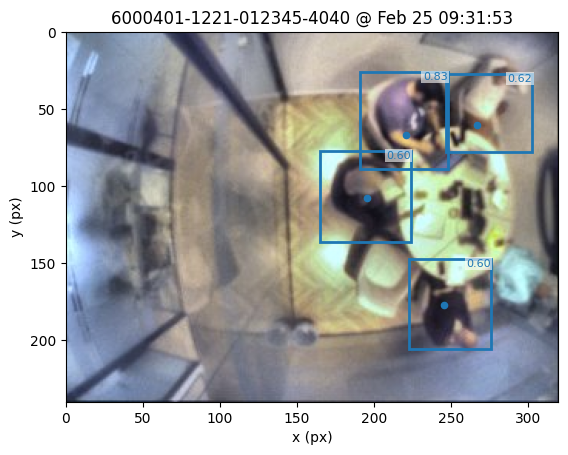

In [13]:
msg = telemetry_messages[6]
msg.plot(image_path="imgs/image.jpeg")


<AxesSubplot: title={'center': '6000401-1221-012345-4040 @ Feb 25 09:31:30'}, xlabel='x (px)', ylabel='y (px)'>

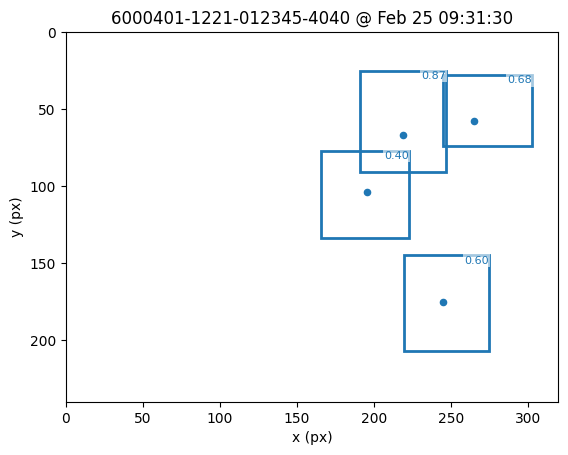

In [7]:
msg = telemetry_messages[0]
msg.plot()